In [2]:
import os
import json
import yaml
import numpy as np
import librosa
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob

In [3]:
# Definimos primero el mapeo que ya acordamos
# Mapeo de instrumentos originales a categorías agrupadas
instrument_mapping = {
    # Clases individuales grandes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Otras cuerdas frotadas
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Vientos madera
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Vientos metal
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Otra percusión
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Otras cuerdas pulsadas
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Instrumentos de lengüetas
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Efectos y sonidos procesados
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# Lista de instrumentos a descartar completamente
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Categorías finales
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapeo de categorías a índices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

In [ ]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Crea un histograma horizontal con las frecuencias de los instrumentos.
    
    Args:
        instrument_counts: Diccionario con instrumento como clave y frecuencia como valor
        top_n: Mostrar solo los top N instrumentos más frecuentes (por defecto 20)
        min_count: Umbral mínimo de apariciones para incluir un instrumento
    """
    # Ordenar instrumentos por frecuencia (mayor a menor)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filtrar según los parámetros
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separar nombres y conteos para el gráfico
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Crear figura con tamaño adaptado al número de instrumentos
    plt.figure(figsize=(10, max(8, len(names) * 0.3)))
    
    # Crear barras horizontales
    plt.barh(names, counts, color='skyblue')
    
    # Añadir etiquetas y título
    plt.xlabel('Número de apariciones')
    plt.title('Frecuencia de instrumentos en MedleyDB')
    
    # Ajustar márgenes
    plt.tight_layout()
    
    # Añadir el valor numérico al final de cada barra
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Mostrar el gráfico
    plt.show()
    
def sanitize_directory_name(name):
    """
    Convierte un nombre de instrumento en un nombre de directorio seguro.
    
    Args:
        name: Nombre original del instrumento
        
    Returns:
        str: Nombre sanitizado seguro para usar como nombre de directorio
    """
    # Reemplazar caracteres problemáticos
    replacements = {
        '/': '_slash_',
        '\\': '_backslash_',
        ':': '_colon_',
        '*': '_star_',
        '?': '_question_',
        '"': '_quote_',
        '<': '_lt_',
        '>': '_gt_',
        '|': '_pipe_',
        ' ': '_'  # También reemplazamos espacios por guiones bajos
    }
    
    result = name
    for char, replacement in replacements.items():
        result = result.replace(char, replacement)
    
    return result

def desanitize_directory_name(sanitized_name):
    """
    Convierte un nombre de directorio sanitizado de vuelta al nombre original.
    
    Args:
        sanitized_name: Nombre sanitizado del directorio
        
    Returns:
        str: Nombre original del instrumento
    """
    # Reemplazar en orden inverso
    replacements = {
        '_slash_': '/',
        '_backslash_': '\\',
        '_colon_': ':',
        '_star_': '*',
        '_question_': '?',
        '_quote_': '"',
        '_lt_': '<',
        '_gt_': '>',
        '_pipe_': '|',
        '_': ' '  # Importante: esto debe ir al final
    }
    
    result = sanitized_name
    for replacement, char in replacements.items():
        result = result.replace(replacement, char)
    
    return result

def count_extracted_segments(base_directory="extracted_segments"):
    """
    Cuenta el número de archivos WAV en cada carpeta de instrumento.
    
    Args:
        base_directory: Directorio base donde se encuentran las carpetas de instrumentos
        
    Returns:
        OrderedDict: Diccionario ordenado con los conteos por instrumento (mayor a menor)
    """
    if not os.path.exists(base_directory):
        print(f"Error: El directorio {base_directory} no existe")
        return {}
    
    # Obtener todas las carpetas (cada una representa un instrumento)
    instrument_dirs = [d for d in os.listdir(base_directory) 
                      if os.path.isdir(os.path.join(base_directory, d))]
    
    # Contar archivos por instrumento
    counts = {}
    total_files = 0
    
    for dir_name in instrument_dirs:
        instrument = desanitize_directory_name(dir_name)
        # Convertir el nombre del directorio de vuelta al nombre del instrumento
        instrument = dir_name.replace("_", " ")
        
        # Contar archivos WAV en esta carpeta
        instrument_path = os.path.join(base_directory, dir_name)
        files = [f for f in os.listdir(instrument_path) 
                if f.endswith(".wav") and os.path.isfile(os.path.join(instrument_path, f))]
        
        num_files = len(files)
        counts[instrument] = num_files
        total_files += num_files
    
    # Ordenar por número de archivos (de mayor a menor)
    sorted_counts = OrderedDict(sorted(counts.items(), key=lambda x: x[1], reverse=True))
    
    # Mostrar resumen
    print(f"Total de segmentos extraídos: {total_files}")
    print("\nSegmentos por instrumento:")
    for instrument, count in sorted_counts.items():
        print(f"- {instrument}: {count} segmentos")
    
    return sorted_counts

def get_class_idx(original_instrument_name):
    # Aplicar desanitize al nombre del instrumento
    instrument_name = desanitize_directory_name(original_instrument_name)
    
    if instrument_name in instruments_to_discard:
        return None
    
    # Reemplazar espacios por guiones bajos si es necesario
    normalized_name = instrument_name.replace(" ", "_")
    
    if normalized_name in instrument_mapping:
        category = instrument_mapping[normalized_name]
        return category_to_idx[category]
    else:
        # Si no está en el mapeo, verificamos si el nombre original está
        if original_instrument_name in instrument_mapping:
            category = instrument_mapping[original_instrument_name]
            return category_to_idx[category]
        return None
    

    def get_metadata_file_path(track_name):
    """Obtiene la ruta al archivo de metadatos YAML para una pista"""
    return os.path.join(MEDLEYDB_ROOT, "Audio", track_name, f"{track_name}_METADATA.yaml")

def extract_track_instruments(track_names):
    """
    Extrae los instrumentos para cada track en el orden de sus STEMs.
    
    Args:
        track_names: Lista de nombres de pistas
        
    Returns:
        list: Lista de listas, donde cada sublista contiene los instrumentos 
              en orden de STEM para un track
    """
    all_instruments = []
    
    for track_name in track_names:
        metadata_path = get_metadata_file_path(track_name)
        
        if not os.path.exists(metadata_path):
            print(f"Advertencia: No se encontró metadatos para {track_name}")
            # Añadir lista vacía para mantener alineación con track_names
            all_instruments.append([])
            continue
            
        try:
            with open(metadata_path, 'r') as f:
                metadata = yaml.safe_load(f)
            
            # Extraer instrumentos en orden de STEM
            instruments = []
            
            if 'stems' in metadata:
                # Ordenar STEMs por número (S01, S02, etc.)
                stem_ids = sorted(metadata['stems'].keys())
                
                for stem_id in stem_ids:
                    stem_data = metadata['stems'][stem_id]
                    if 'instrument' in stem_data:
                        instrument = stem_data['instrument']
                        instruments.append(instrument)
            
            all_instruments.append(instruments)
            print(f"Processed: {track_name} - {len(instruments)} instruments")
            
        except Exception as e:
            print(f"Error al procesar {track_name}: {e}")
            all_instruments.append([])  # Lista vacía en caso de error
    
    return all_instruments

def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Crea un histograma horizontal con las frecuencias de los instrumentos.
    
    Args:
        instrument_counts: Diccionario con instrumento como clave y frecuencia como valor
        top_n: Mostrar solo los top N instrumentos más frecuentes (por defecto 20)
        min_count: Umbral mínimo de apariciones para incluir un instrumento
    """
    # Ordenar instrumentos por frecuencia (mayor a menor)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filtrar según los parámetros
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separar nombres y conteos para el gráfico
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Crear figura con tamaño adaptado al número de instrumentos
    plt.figure(figsize=(10, max(8, len(names) * 0.3)))
    
    # Crear barras horizontales
    plt.barh(names, counts, color='skyblue')
    
    # Añadir etiquetas y título
    plt.xlabel('Número de apariciones')
    plt.title('Frecuencia de instrumentos en MedleyDB')
    
    # Ajustar márgenes
    plt.tight_layout()
    
    # Añadir el valor numérico al final de cada barra
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Mostrar el gráfico
    plt.show()

def get_activation_intervals(track_name, instrument):
    """
    Obtiene los intervalos de activación para un instrumento específico.
    
    Args:
        track_name: Nombre del track
        instrument: Nombre del instrumento
        
    Returns:
        list: Lista de tuplas (start_time, end_time)
    """
    sourceid_path = os.path.join(SOURCEID_DIR, f"{track_name}_SOURCEID.lab")
    
    intervals = []
    if os.path.exists(sourceid_path):
        with open(sourceid_path, 'r') as f:
            header = f.readline()  # Saltar encabezado
            for line in f:
                parts = line.strip().split(',')
                if len(parts) >= 3 and parts[2].strip() == instrument:
                    start_time = float(parts[0])
                    end_time = float(parts[1])
                    intervals.append((start_time, end_time))
    
    return intervals

def get_stem_path(track_name, instrument):
    """
    Obtiene la ruta al archivo STEM para un instrumento específico.
    
    Args:
        track_name: Nombre del track
        instrument: Nombre del instrumento
        
    Returns:
        str: Ruta al archivo STEM
    """
    # 1. Obtener los metadatos para encontrar qué STEM corresponde a este instrumento
    metadata_path = get_metadata_file_path(track_name)
    
    with open(metadata_path, 'r') as f:
        metadata = yaml.safe_load(f)
    
    # 2. Buscar el STEM ID que corresponde a este instrumento
    stem_id = None
    for stem, data in metadata['stems'].items():
        if data.get('instrument') == instrument:
            stem_id = stem
            break
    
    if stem_id is None:
        return None
    
    # 3. Construir la ruta al archivo STEM
    stem_number = stem_id[1:] if stem_id.startswith('S') else stem_id
    return os.path.join(AUDIO_DIR, track_name, f"{track_name}_STEMS", 
                       f"{track_name}_STEM_{stem_number}.wav")

def extract_audio_segments(track_name, instrument, segment_duration=3.0, overlap=0.5):
    """
    Extrae segmentos de audio de duración fija para un instrumento específico.
    
    Args:
        track_name: Nombre del track
        instrument: Nombre del instrumento
        segment_duration: Duración de cada segmento en segundos
        overlap: Solapamiento entre segmentos consecutivos
        
    Returns:
        list: Lista de arrays NumPy con los segmentos de audio
    """
    # 1. Obtener intervalos de activación
    intervals = get_activation_intervals(track_name, instrument)
    
    # 2. Obtener la ruta al archivo STEM
    stem_path = get_stem_path(track_name, instrument)
    
    if stem_path is None or not os.path.exists(stem_path):
        print(f"No se encontró archivo STEM para {instrument} en {track_name}")
        return []
    
    # 3. Extraer segmentos de audio
    segments = []
    for start_time, end_time in intervals:
        duration = end_time - start_time
        ##print(duration)
        
        # Saltamos intervalos demasiado cortos
        if duration < segment_duration:
            continue
            
        # Cargar el audio
        try:
            y, sr = librosa.load(stem_path, sr=44100, offset=start_time, duration=duration)
            
            # Extraer segmentos con solapamiento
            step = segment_duration * (1 - overlap)
            t = 0.0
            
            while t + segment_duration <= duration:
                segment_start = int(t * sr)
                segment_end = int((t + segment_duration) * sr)
                
                if segment_end <= len(y):
                    segment = y[segment_start:segment_end]
                    segments.append(segment)
                
                t += step
                
        except Exception as e:
            print(f"Error al procesar audio {stem_path}: {e}")
    
    return segments

def extract_and_save_segments(instrument_counts, track_names, all_instruments, 
                             segment_duration=3.0, overlap=0.5,
                             top_n=None):
    """
    Extrae y guarda segmentos de audio para instrumentos seleccionados.
    """
    # Directorio fijo para guardar
    extracted_directory = "extracted_segments"
    os.makedirs(extracted_directory, exist_ok=True)
    
    # Seleccionar instrumentos (top N más frecuentes)
    sorted_instruments = sorted(instrument_counts.items(), 
                              key=lambda x: x[1], reverse=True)
    
    if top_n is not None:
        selected_instruments = [item[0] for item in sorted_instruments[:top_n]]
    else:
        selected_instruments = [item[0] for item in sorted_instruments]
    
    print(f"Procesando {len(selected_instruments)} instrumentos seleccionados")
    
    # Procesar cada instrumento seleccionado
    for instrument in tqdm(selected_instruments, desc="Instrumentos"):
        # Sanitizar el nombre del instrumento para el directorio
        instrument_dir_name = sanitize_directory_name(instrument)
        instrument_directory = os.path.join(extracted_directory, instrument_dir_name)
        os.makedirs(instrument_directory, exist_ok=True)
        
        # Contador para segmentos totales de este instrumento
        total_segments = 0
        
        # Procesar cada canción
        for i, track_name in enumerate(tqdm(track_names, desc=f"Canciones para {instrument}", leave=False)):
            # Verificar si este instrumento está en esta canción
            if instrument in all_instruments[i]:
                try:
                    # CORRECCIÓN: Solo un valor devuelto
                    segments = extract_audio_segments(track_name, instrument, 
                                                    segment_duration, overlap)
                    
                    # Frecuencia de muestreo fija para guardar
                    sr = 44100
                    
                    # Guardar cada segmento
                    for j, segment in enumerate(segments):
                        # Nombre de archivo: artista_cancion_nnn.wav
                        filename = f"{track_name}_{j:03d}.wav"
                        filepath = os.path.join(instrument_directory, filename)
                        
                        # Guardar como archivo WAV
                        sf.write(filepath, segment, sr)
                        total_segments += 1
                
                except Exception as e:
                    print(f"\nError al procesar {track_name}, {instrument}: {e}")
        
        print(f"\n- {instrument}: {total_segments} segmentos guardados")

def process_and_save_features(base_dir="extracted_segments", feature_types=["cqt", "mel"]):
    """
    Procesa los archivos WAV y guarda las matrices de características con 
    dimensiones (96, 128) - 96 bins de frecuencia y 128 frames temporales.
    
    Args:
        base_dir: Directorio base que contiene las carpetas de instrumentos
        feature_types: Lista de tipos de características a calcular ("cqt", "mel")
    """
    # Parámetros para las características
    sr = 44100  # Frecuencia de muestreo
    n_fft = 2048  # Tamaño de la FFT
    hop_length = 1024  # Para obtener aproximadamente 130 frames en 3 segundos
    
    # Configuración específica para CQT
    cqt_params = {
        'n_bins': 96,             # 96 bins según el paper
        'bins_per_octave': 12,    # 12 semitonos por octava (8 octavas)
        'hop_length': hop_length,
        'fmin': librosa.note_to_hz('C1')  # Comenzar desde C1
    }
    
    # Configuración específica para Mel-espectrograma
    mel_params = {
        'n_mels': 96,             # 96 bins según el paper
        'n_fft': n_fft,
        'hop_length': hop_length
    }
    
    # Obtener todas las carpetas de instrumentos
    instrument_dirs = [d for d in os.listdir(base_dir) 
                      if os.path.isdir(os.path.join(base_dir, d))]
    
    # Procesar cada carpeta de instrumento
    for instrument_dir in tqdm(instrument_dirs, desc="Procesando instrumentos"):
        instrument_path = os.path.join(base_dir, instrument_dir)
        
        # Obtener todos los archivos WAV
        wav_files = [f for f in os.listdir(instrument_path) 
                    if f.endswith(".wav") and os.path.isfile(os.path.join(instrument_path, f))]
        
        # Procesar cada archivo WAV
        for wav_file in tqdm(wav_files, desc=f"Archivos en {instrument_dir}"):#leave=False
            wav_path = os.path.join(instrument_path, wav_file)
            
            # Crear nombre base sin extensión
            base_name = os.path.splitext(wav_file)[0]
            
            # Crear carpeta para guardar características
            features_dir = os.path.join(instrument_path, base_name)
            os.makedirs(features_dir, exist_ok=True)
            
            # Cargar el audio
            try:
                audio, sr_file = sf.read(wav_path)
                
                # Convertir a mono si es estéreo
                if len(audio.shape) > 1 and audio.shape[1] > 1:
                    audio = np.mean(audio, axis=1)
                
                # Remuestrear si es necesario
                if sr_file != sr:
                    audio = librosa.resample(audio, orig_sr=sr_file, target_sr=sr)
                
                # Calcular y guardar cada tipo de característica
                for feature_type in feature_types:
                    if feature_type == "cqt":
                        # Calcular CQT
                        C = librosa.cqt(audio, sr=sr, **cqt_params)
                        log_C = librosa.amplitude_to_db(np.abs(C))
                        
                        # Ajustar a exactamente 128 frames
                        '''
                        if log_C.shape[1] > 128:
                            log_C = log_C[:, :128]
                        elif log_C.shape[1] < 128:
                            padding = np.zeros((log_C.shape[0], 128 - log_C.shape[1]))
                            log_C = np.hstack([log_C, padding])
                        '''
                        
                        # Verificar dimensiones finales
                        ## assert log_C.shape == (96, 128), f"Dimensiones incorrectas: {log_C.shape}"
                        
                        # Guardar matriz CQT
                        feature_name = f"cqt_{cqt_params['n_bins']}bins_hop{hop_length}.npy"
                        np.save(os.path.join(features_dir, feature_name), log_C)
                        
                    elif feature_type == "mel":
                        # Calcular mel-espectrograma
                        S = librosa.feature.melspectrogram(y=audio, sr=sr, **mel_params)
                        log_S = librosa.power_to_db(S)
                        
                        # Ajustar a exactamente 128 frames
                        # Can be eliminated
                        '''
                        if log_S.shape[1] > 128:
                            log_S = log_S[:, :128]
                        elif log_S.shape[1] < 128:
                            padding = np.zeros((log_S.shape[0], 128 - log_S.shape[1]))
                            log_S = np.hstack([log_S, padding])
                        '''
                        
                        # Verificar dimensiones finales
                        # assert log_S.shape == (96, 128), f"Dimensiones incorrectas: {log_S.shape}"
                        
                        # Guardar matriz Mel
                        feature_name = f"mel_{mel_params['n_mels']}bins_hop{hop_length}.npy"
                        np.save(os.path.join(features_dir, feature_name), log_S)
            
            except Exception as e:
                print(f"\nError al procesar {wav_path}: {e}")

Total de segmentos extraídos: 69653

Segmentos por instrumento:
- electric bass: 6781 segmentos
- drum set: 6300 segmentos
- piano: 5039 segmentos
- clean electric guitar: 4790 segmentos
- synthesizer: 4594 segmentos
- tabla: 3707 segmentos
- fx slash processed sound: 3415 segmentos
- violin: 3010 segmentos
- drum machine: 2917 segmentos
- male singer: 2776 segmentos
- distorted electric guitar: 2475 segmentos
- acoustic guitar: 2452 segmentos
- female singer: 2190 segmentos
- vocalists: 1565 segmentos
- mandolin: 1502 segmentos
- auxiliary percussion: 1442 segmentos
- double bass: 1440 segmentos
- accordion: 1260 segmentos
- cello: 1106 segmentos
- viola: 875 segmentos
- flute: 622 segmentos
- tack piano: 565 segmentos
- string section: 504 segmentos
- clarinet: 444 segmentos
- vibraphone: 440 segmentos
- violin section: 440 segmentos
- harp: 424 segmentos
- brass section: 384 segmentos
- male rapper: 384 segmentos
- cymbal: 349 segmentos
- horn section: 319 segmentos
- bassoon: 298 s

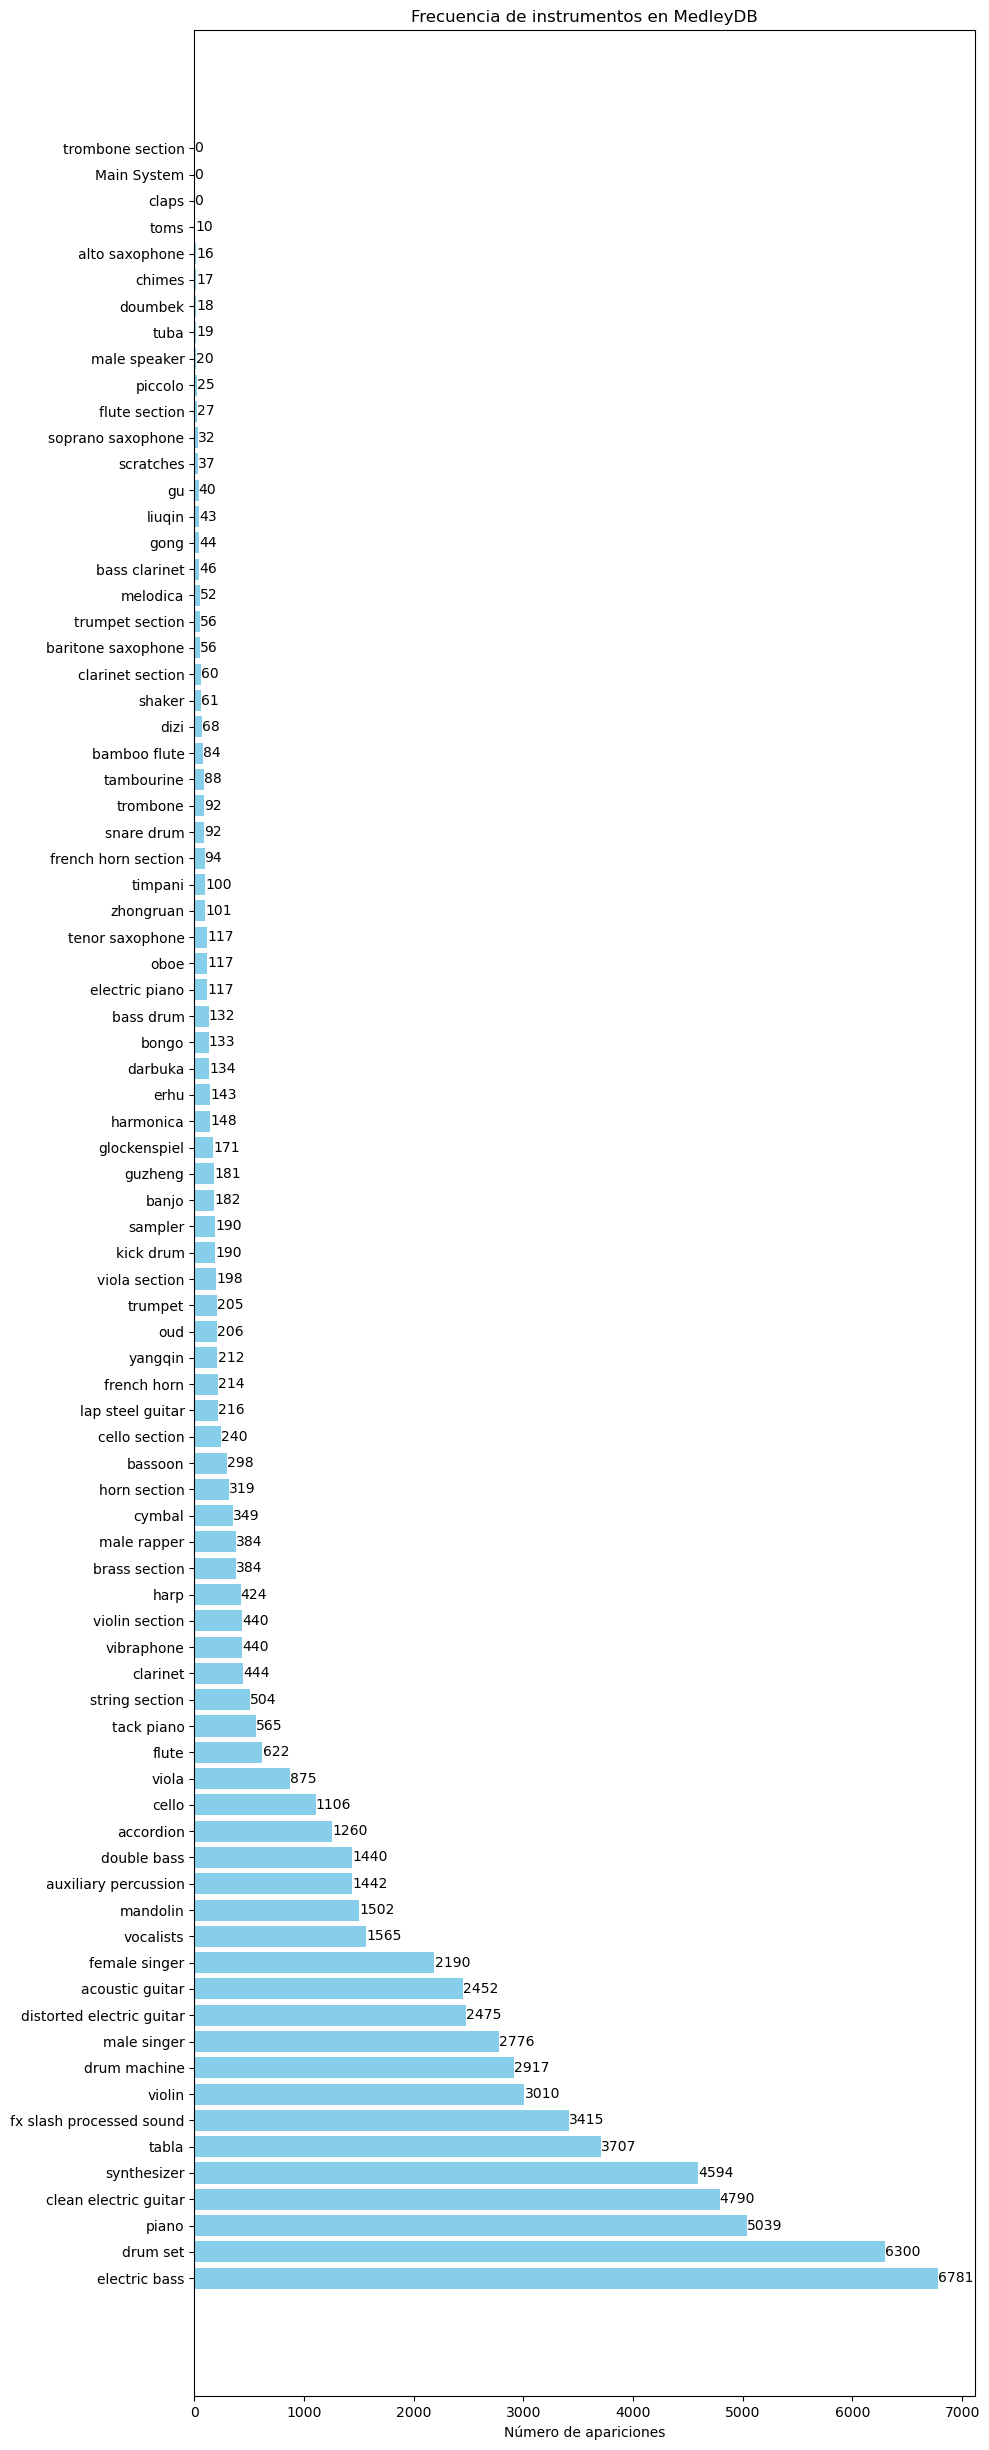

In [5]:
segments_per_instrument = count_extracted_segments()
plot_instrument_histogram(segments_per_instrument,top_n =82)

In [6]:
# Importaciones necesarias
import os
import numpy as np
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

# Configuración
base_path = os.path.normpath("extracted_segments")  # Normalizar la ruta
feature_type = "cqt"  # o "mel"
test_size = 0.2
random_state = 42

# Determinar el archivo de características
if feature_type == "cqt":
    feature_filename = "cqt_96bins_hop1024.npy"
elif feature_type == "mel":
    feature_filename = "mel_96bins_hop1024.npy"
else:
    raise ValueError(f"Tipo de característica no soportado: {feature_type}")

# Obtener la lista de instrumentos (carpetas)
instrument_dirs = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]

# Listas para almacenar datos
features = []
labels = []
instrument_counts = {category: 0 for category in instrument_categories}
instrument_counts["unknown"] = 0  # Añadir categoría unknown para manejar casos no mapeados
skipped_instruments = {}

print(f"Cargando características {feature_type} con el esquema de clasificación definido...")

# Recorrer cada carpeta de instrumento
for instrument_dir in tqdm(instrument_dirs):
    # Usar os.path.join para construir rutas de manera segura en cualquier plataforma
    instrument_path = os.path.join(base_path, instrument_dir)
    
    # Verificar si este instrumento debe incluirse
    class_idx = get_class_idx(instrument_dir)
    
    if class_idx is None:
        skipped_instruments[instrument_dir] = "instrumento descartado"
        continue
    
    try:
        # Buscar todas las subcarpetas que contienen características
        feature_folders = [d for d in os.listdir(instrument_path) 
                          if os.path.isdir(os.path.join(instrument_path, d))]
        
        # Cargar cada archivo de características
        for folder in feature_folders:
            # Construir la ruta del archivo de forma segura
            feature_file = os.path.join(instrument_path, folder, feature_filename)
            feature_file = os.path.normpath(feature_file)  # Normalizar la ruta
            
            if os.path.exists(feature_file):
                # Cargar el archivo .npy
                feature_data = np.load(feature_file)
                
                # Añadir a nuestras listas
                features.append(feature_data)
                labels.append(class_idx)
                
                # Incrementar contador para esta categoría
                category = instrument_mapping.get(instrument_dir, "unknown")
                if category in instrument_counts:
                    instrument_counts[category] += 1
                else:
                    instrument_counts[category] = 1
            else:
                if instrument_dir not in skipped_instruments:
                    skipped_instruments[instrument_dir] = f"archivo no encontrado: {feature_file}"
    except Exception as e:
        print(f"Error al procesar {instrument_path}: {type(e).__name__}: {e}")
        skipped_instruments[instrument_dir] = f"error: {str(e)}"
        continue

Cargando características cqt con el esquema de clasificación definido...


  0%|          | 0/82 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [7]:
# Después de procesar todos los datos
X = np.array(features)
y = np.array(labels)

# Guardar solo los arrays
np.save(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'), X)  # o cqt
np.save(os.path.join('extracted_segments_features', 'processed_labels_cqt.npy'), y)

print(f"Datos guardados: {X.shape} características y {y.shape} etiquetas")

Datos guardados: (735, 96, 130) características y (735,) etiquetas


In [ ]:
instrument_counts

{'electric_bass': 6781,
 'drum_set': 6300,
 'piano': 5604,
 'synthesizer': 4711,
 'clean_electric_guitar': 4790,
 'distorted_electric_guitar': 2475,
 'acoustic_guitar': 2452,
 'violin': 3010,
 'female_singer': 2190,
 'vocalists': 1565,
 'male_vocals': 3180,
 'other_bowed_strings': 4946,
 'woodwinds': 1860,
 'brass': 1383,
 'other_percussion': 9085,
 'other_plucked_strings': 3635,
 'reed_instruments': 1460,
 'fx_and_processed': 3452,
 'unknown': 0}

In [ ]:
BASE_DIR = "."  


MEDLEYDB_ROOT = os.path.join(BASE_DIR, "MedleyDB")
AUDIO_DIR = os.path.join(MEDLEYDB_ROOT, "Audio")
ANNOTATIONS_DIR = os.path.join(MEDLEYDB_ROOT, "Annotations")


INSTRUMENT_ACTIVATIONS_DIR = os.path.join(ANNOTATIONS_DIR, "Instrument_Activations")
ACTIVATION_CONF_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "ACTIVATION_CONF")
SOURCEID_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "SOURCEID")

In [ ]:
if not os.path.exists(AUDIO_DIR):
    print(f"Error: Directory {AUDIO_DIR} does not exist.")
# Obtener solo los directorios (ignorar archivos)
else:
    track_names = [item for item in os.listdir(AUDIO_DIR) if os.path.isdir(os.path.join(AUDIO_DIR, item))]
    print(f" {len(track_names)} songs where found.")

In [ ]:
all_instruments = extract_track_instruments(track_names) # all_instruments[i][j] i instrument, j stem

In [ ]:
instrument_counts = {}

# Recorrer todas las listas de instrumentos
for track_instruments in all_instruments:
    for instrument in track_instruments:
        if instrument in instrument_counts:
            instrument_counts[instrument] += 1
        else:
            instrument_counts[instrument] = 1

# Obtener conteo de instrumentos
unique_count = len(instrument_counts)

# Ordenar instrumentos por frecuencia (de mayor a menor)
sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)

# Mostrar resultados

print(f"\nTotal de instrumentos únicos en el dataset: {unique_count}")
print("\nInstrumentos ordenados por frecuencia:")
for i, (instrument, count) in enumerate(sorted_instruments):
    print(f"{i+1}. {instrument}: {count} tracks")

In [ ]:
# Crear histograma de los 20 instrumentos más frecuentes
plot_instrument_histogram(instrument_counts, top_n=20)

# Alternativa: mostrar solo instrumentos con al menos 5 apariciones
# plot_instrument_histogram(instrument_counts, top_n=None, min_count=5)

In [ ]:
extract_and_save_segments(
    instrument_counts=instrument_counts,
    track_names=track_names,
    all_instruments=all_instruments,
    segment_duration=3.0,
    overlap=0.5,
    top_n=83  # Limitar a los 10 instrumentos más frecuentes
)

In [ ]:
# Ejemplo de uso
segments_per_instrument = count_extracted_segments()
plot_instrument_histogram(segments_per_instrument,top_n =30)

In [ ]:
process_and_save_features(
    base_dir="extracted_segments", 
    feature_types=["cqt"]
)